# Лекция: Компьютерное зрение
## Image Segmentation (part 2)

**Преподаватель:** Шевченко Елена, Т-Банк

**Аудитория:** МФТИ

---
### Оглавление
~~Part 1. Bacis: Задача, Метрики, Лоссы + Семантическая сегментация~~
- ~~1. Постановка задачи~~
- ~~2. Метрики~~
- ~~3. Функции потерь~~
- ~~4. Семантическая сегментация: U-Net, FPN, PAN, U-Net++, U²-Net, DeepLab v3, пример обучения~~


Part 2. Instance + Transformers
- Instance segmentation: Mask R-CNN, Deep Watershed
- Трансформеры в сегментации: SETR, SegFormer, Mask2Former


Part 3. SAM
- задача
- архитектура
- обучение, данные
- SAM 2 и SAM 3

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
import timm
from transformers import (
    Mask2FormerForUniversalSegmentation,
    Mask2FormerImageProcessor,
    SegformerForSemanticSegmentation,
    SegformerImageProcessor,
)

%matplotlib inline

# 5. Instance Segmentation

Нужно не только классифицировать пиксели, но и **разделить объекты одного класса**.
Два больших семейства:
- **«сначала найди объект, потом сегментируй»**: Mask R-CNN и его потомки;
- **«сначала сегментируй, потом раздели»** : попиксельные предсказания + группировка пикселей в объекты, например Deep Watershed.

Третий путь — **query-based** модели (Mask2Former), они в разделе Transformers.

## 5.1 Mask R-CNN (He et al., 2017)

Mask R-CNN — расширение **Faster R-CNN** (см. лекцию про детекцию): к ветвям класса и бокса добавлена ветвь **маски** для каждого RoI.

![mask-rcnn](assets/mask-rcnn.png)

#### 1. Backbone + FPN

Backbone (ResNet / ResNeXt) даёт $\{C_2, C_3, C_4, C_5\}$, FPN строит пирамиду:

$$
M_5 = \text{Conv}_{1\times1}(C_5), \quad
M_l = \text{Conv}_{1\times1}(C_l) + \text{Up}(M_{l+1}), \quad
P_l = \text{Conv}_{3\times3}(M_l)
$$

$C_l$ — признаки backbone уровня $l$. Пирамида $\{P_2, \dots, P_5\}$ (+ $P_6$ для RPN) используется и RPN, и головами.

#### 2. Region Proposal Network (RPN)

- Генерирует candidate regions (RoIs) с вероятностью, что объект присутствует:

$$
\{B_i\} = \text{RPN}(F)
$$

- $3\times3$ conv по каждому уровню пирамиды → два $1\times1$ conv: **objectness** и **поправки к anchor-боксам**;
- после NMS — набор кандидатов (RoI) $\{B_i\}$.

#### 3. RoI Align

- RoI Pooling **округлял** координаты RoI и ячеек → смещение признаков на доли пикселя, для масок это критично;
- RoI Align берёт признаки в нецелых точках **билинейной интерполяцией**, без округлений;

$$
F_i^{\text{roi}} = \text{RoIAlign}(F, B_i, H \times W)
$$

- RoI выбирает уровень пирамиды по своему размеру; выход фиксированного размера: $7\times7$ для головы бокса, $14\times14$ для головы маски.

#### 4. Mask Head

Маленькая FCN поверх RoI-признаков $14\times14$:

$$
\underbrace{4 \times [\text{Conv}_{3\times3} \to \text{ReLU}]}_{14\times14\times256}
\;\to\; \text{ConvTranspose}_{2\times2,\ stride 2} \;\to\; \text{Conv}_{1\times1}
\;\to\; M_i \in \mathbb{R}^{K \times 28 \times 28}
$$

- предсказывается **$K$ масок — по одной на каждый класс**, с **попиксельной sigmoid** (не softmax по классам);
- в loss берётся только маска **истинного** класса объекта, на инференсе — маска предсказанного класса;
- так задачи «какой класс» и «какая форма» **развязаны**: маски разных классов не конкурируют (в статье softmax-вариант заметно хуже);
- маска $28\times28$ затем ресайзится в размер бокса и бинаризуется по порогу 0.5.

#### 5. Box & Class Head

Стандартные ветви Faster R-CNN: $p_i = \text{softmax}(\text{FC}(F_i^{roi}))$ — класс (с фоном), $\text{FC}(F_i^{roi})$ — уточнение бокса.

#### Loss

$$
\mathcal{L} = \mathcal{L}_{cls} + \mathcal{L}_{box} + \mathcal{L}_{mask}
$$

- $\mathcal{L}_{cls}$ — cross-entropy по классам;
- $\mathcal{L}_{box}$ — smooth L1 по координатам;
- $\mathcal{L}_{mask}$ — средняя попиксельная BCE по маске $28\times28$ **истинного** класса.

#### Плюсы и минусы

- `+` точное разделение экземпляров, сильный и проверенный baseline, легко расширяется (keypoints, DensePose)
- `-` двухстадийный, вычисления на каждый RoI; маска всего $28\times28$ → грубые границы у больших объектов;
  маска ограничена боксом: ошибка детектора = ошибка маски

## 5.2 Deep Watershed Transform (Bai & Urtasun, 2017)

### Классический Watershed

![watershed](assets/watershed.png)

**Идея:** смотрим на изображение (обычно на модуль градиента) как на **рельеф**: значения — высоты.
- «Заливаем водой» из **маркеров/низин** (локальных минимумов или заданных точек);
- там, где вода из разных бассейнов встречается, проводится **граница** (watershed line).

**Типичный приём: разделение слипшихся объектов**

Бинарная маска уже есть, но объекты слиплись и нужно провести границу между ними.

Шаг 1 — Distance transform:  
Для каждого пикселя объекта считаем расстояние до ближайшего фона.
Результат: максимумы в центрах объектов, 0 на границах.

Шаг 2 — Маркеры: 
Пики distance transform — по одному на каждый объект — становятся маркерами.

Шаг 3 — Watershed на -distance transform:
Берём минус, чтобы центры стали минимумами (вода заливается из центров).
Запускаем watershed внутри маски — граница проходит там, где воды из разных центров встречаются.


**Проблемы:** чувствителен к шуму (пересегментация — много мелких сегментов), сам по себе не использует семантику.

---

### Deep Watershed Transform (DWT)

!### Deep Watershed Transform (DWT)
![deep_watershed](assets/deep_watershed.png)

**Задача:** instance segmentation без боксов — нужно разделить отдельные экземпляры объектов
(например, слипшиеся клетки на одной маске).

**Идея:** пусть сеть предскажет идеальный рельеф («энергию»), где каждый объект —
отдельная яма без шума. Тогда watershed сработает тривиально.

#### Энергия
Расстояние до ближайшей границы объекта, дискретизированное на $K=16$ уровней:

| уровень | где |
|---|---|
| 0 | фон и граница объекта (дно рва) |
| 15 | середина объекта (пик) |

Соседние объекты разделены «рвом» из нулей — watershed легко находит границу между ними.

#### Архитектура (две последовательные сети)

Предсказывать энергию напрямую сложно, поэтому задачу разбили на два шага:

**1. Direction Network** (на базе VGG16):
предсказывает в каждом пикселе единичный вектор **от ближайшей границы к центру объекта**.

**2. Watershed Transform Network:**
по полю направлений предсказывает уровень энергии (классификация по 16 уровням).
Зная направления, предсказывать уровни проще, чем напрямую из RGB.

#### Полный пайплайн

```
RGB
 ↓
PSPNet → семантическая маска (что где: люди, машины...)
 ↓                                    ↓
 └──── RGB, «загейченный» маской ─────┘
       (сеть работает только с пикселями нужного класса)
 ↓
Direction Network → поле направлений (←↑→↓ для каждого пикселя)
 ↓
Watershed Transform Network → карта энергии (16 уровней)
 ↓
срезаем на уровне 1–2 → связные компоненты → отдельные объекты
 ↓
dilation → возвращаем срезанную полосу у границы
```

#### Плюсы и минусы
- "+" нет боксов и RoI, хорошо разделяет плотно стоящие объекты, простой постпроцессинг
- "-" нужна хорошая семантическая сегментация на входе; объекты, разделённые
  окклюзией на части, распадаются на разные компоненты

> На практике часто используют упрощённую схему **«U-Net + watershed»**:
> сеть предсказывает маску и карту расстояния/энергии,
> дальше — классический watershed (например, в сегментации клеток и ядер).

связных компонент в маске: 1 | объектов после watershed: 2


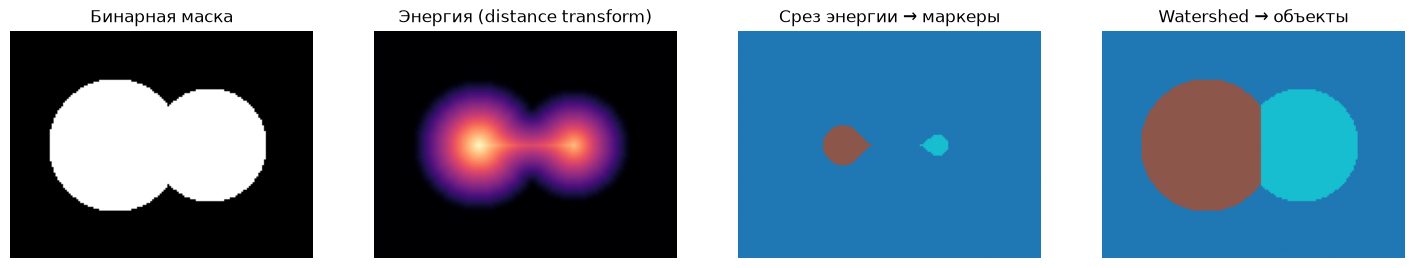

In [2]:
from scipy import ndimage as ndi
from skimage.measure import label
from skimage.segmentation import watershed

# Бинарная маска: два перекрывающихся круга -> одна связная компонента
yy, xx = np.mgrid[:120, :160]
mask = ((yy - 60) ** 2 + (xx - 55) ** 2 < 35**2) | ((yy - 60) ** 2 + (xx - 105) ** 2 < 30**2)

# "Энергия" как в DWT: расстояние до границы — высоко в центрах, 0 на краю
energy = ndi.distance_transform_edt(mask)

# Срез на уровне энергии -> связные компоненты = маркеры объектов
markers = label(energy > 0.7 * energy.max())

# Watershed по -energy (центры = минимумы), только внутри маски
instances = watershed(-energy, markers, mask=mask)

print("связных компонент в маске:", label(mask).max(), "| объектов после watershed:", instances.max())
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for ax, im, title, cmap in zip(
    axs,
    [mask, energy, markers, instances],
    ["Бинарная маска", "Энергия (distance transform)", "Срез энергии → маркеры", "Watershed → объекты"],
    ["gray", "magma", "tab10", "tab10"],
):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

# 6. Transformers in Segmentation

Напоминание про **ViT**: картинка режется на патчи $P \times P$ (обычно $P = 16$), каждый патч линейно проецируется в токен размерности $D$:

$$
z_0 = [\,x_{cls};\; x^1_p E;\; \dots;\; x^N_p E\,] + E_{pos}, \qquad N = \frac{HW}{P^2}
$$

$$
z_l' = z_{l-1} + \text{MHSA}(\text{LN}(z_{l-1})), \qquad z_l = z_l' + \text{MLP}(\text{LN}(z_l'))
$$

Для сегментации выход encoder $Z \in \mathbb{R}^{N \times D}$ (без cls-токена) складывается обратно в 2D-карту
$\mathbb{R}^{H/P \times W/P \times D}$ — это **одна** карта с разрешением 1/16, без пирамиды масштабов.
Главный вопрос всех архитектур ниже — как из этого получить точную маску $H \times W$.

## 6.1 SETR (Zheng et al., CVPR 2021)

*«Rethinking Semantic Segmentation from a Sequence-to-Sequence Perspective with Transformers»*.
![setr](assets/setr.png)

**Encoder:** «чистый» ViT (в статье ViT-L, 24 слоя), без свёрток и без downsampling внутри — все слои работают на 1/16.

**Три варианта decoder:**

- **Naive:** $1\times1$ conv + BN + ReLU + $1\times1$ conv в число классов → билинейный upsample ×16.
- **PUP (Progressive UPsampling):** чередуем conv и upsample **×2**, чтобы не прыгать сразу в 16 раз:
  $1/16 \to 1/8 \to 1/4 \to 1/2 \to 1$ — всего 4 шага.
- **MLA (Multi-Level feature Aggregation):** берём выходы **нескольких слоёв** ViT (через равные промежутки по глубине), каждый — reshape в 2D, $1\times1\space \text{или}\space  3\times3$ conv, затем top-down агрегация (сложение с предыдущим потоком, как в FPN) → upsample ×4 → **concat** → upsample ×4.
  Похоже на FPN, но все «уровни» одного разрешения: разные слои отличаются семантикой, а не масштабом.  
  **Алгоритм:**
  ```
  ViT:      слой 4      слой 8      слой 16     слой 24
              ↓           ↓           ↓           ↓
  reshape:  H/16×W/16  H/16×W/16  H/16×W/16  H/16×W/16
              ↓           ↓           ↓           ↓
  Conv 1×1: 256ch       256ch       256ch       256ch
              ↓           ↓           ↓           ↓
  top-down: +слой 8     +слой 16    +слой 24      —
              ↓           ↓           ↓           ↓
  Up×4:     H/4         H/4         H/4         H/4
              └───────────┴───────────┴───────────┘
                                concat
                                  ↓
                              Conv 3×3
                                  ↓
                              Up×4 → H×W маска
  ```

**Плюсы:** глобальный контекст с первого слоя (attention видит всю картинку); показал, что «чистый» трансформер конкурентен в сегментации.

**Минусы:**
- разрешение признаков всего 1/16 → мелкие объекты и тонкие границы теряются
- ViT-L тяжёлый, сложность attention квадратична по числу токенов → дорого на высоком разрешении;
- требуется большой претрейн.

In [ ]:
class SETRPUP(nn.Module):
    # Decoder SETR-PUP поверх ViT: 4 раза [Conv3x3 -> BN -> ReLU -> Upsample x2], 1/16 -> 1

    def __init__(self, embed_dim: int, num_classes: int, hidden: int = 256) -> None:
        super().__init__()
        layers, in_ch = [], embed_dim
        for _ in range(4):
            layers += [
                nn.Conv2d(in_ch, hidden, 3, padding=1),
                nn.BatchNorm2d(hidden),
                nn.ReLU(inplace=True),
                nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            ]
            in_ch = hidden
        self.decoder = nn.Sequential(*layers, nn.Conv2d(hidden, num_classes, 1))

    def forward(self, tokens: Tensor, grid: tuple[int, int]) -> Tensor:
        b, n, d = tokens.shape
        x = tokens.transpose(1, 2).reshape(b, d, *grid)  # (B, N, D) -> (B, D, H/16, W/16)
        return self.decoder(x)


vit = timm.create_model("vit_base_patch16_224", pretrained=False, num_classes=0)  # только форма, веса не нужны
tokens = vit.forward_features(torch.randn(1, 3, 224, 224))  # (1, 1 + 196, 768): cls + патчи
patch_tokens = tokens[:, vit.num_prefix_tokens:]
print("ViT tokens:", tuple(tokens.shape), "-> patch tokens:", tuple(patch_tokens.shape))

decoder = SETRPUP(embed_dim=vit.embed_dim, num_classes=150)
print("SETR-PUP output:", tuple(decoder(patch_tokens, grid=(14, 14)).shape))

ViT tokens: (1, 197, 768) -> patch tokens: (1, 196, 768)
SETR-PUP output: (1, 150, 224, 224)


## 6.2 SegFormer (Xie et al., NeurIPS 2021)

*«SegFormer: Simple and Efficient Design for Semantic Segmentation with Transformers»*

![segformer](assets/segformer.png)

Две идеи: **иерархический** transformer-encoder (как у CNN — пирамида признаков) и **очень лёгкий All-MLP decoder**. В отличие от SETR, multi-scale признаки формируются **уже на этапе кодирования**, поэтому decoder минималистичный.

### Encoder: Mix Transformer (MiT)

4 стадии с разрешениями $\frac{H}{4}, \frac{H}{8}, \frac{H}{16}, \frac{H}{32}$ и растущим числом каналов $C_1 < C_2 < C_3 < C_4$.

**1. Overlapped Patch Merging.** Патчи нарезаются **с перекрытием** — по сути это свёртка со stride:
$K=7, S=4, P=3$ на первой стадии и $K=3, S=2, P=1$ на остальных. Перекрытие сохраняет локальную непрерывность между патчами.

**2. Efficient Self-Attention.** Attention **глобальный** (не оконный, как в Swin), но последовательность для $K$ и $V$ укорачивается:
strided conv с коэффициентом $R$ по каждой стороне уменьшает $K, V$ в $R^2$ раз, $Q$ остаётся полного размера.

$$
\hat{K} = \text{Reduce}_R(K), \quad \hat V = \text{Reduce}_R(V), \qquad
\text{Attention}(Q, \hat K, \hat V) = \text{Softmax}\Big(\frac{Q \hat K^T}{\sqrt{d}}\Big)\hat V
$$

Сложность $O(N^2) \to O(N^2 / R^2)$; по стадиям $R = 8, 4, 2, 1$ (длина последовательности сокращается в 64, 16, 4, 1 раз).

**3. Mix-FFN вместо positional encoding.** Позиционных эмбеддингов **нет** — их роль играет depthwise-свёртка $3\times3$ внутри FFN:

$$
x_{out} = \text{MLP}\big(\text{GELU}(\text{DWConv}_{3\times3}(\text{MLP}(x_{in})))\big) + x_{in}
$$

Благодаря этому модель спокойно работает на разрешении, отличном от обучающего (нет интерполяции positional encoding, как у ViT).

### Decoder: All-MLP

1. каждый уровень $F_i$ проецируется линейным слоем в общее число каналов $C$;
2. все уровни upsample до $\frac{H}{4} \times \frac{W}{4}$;
3. **конкатенация** ($4C$ каналов) → линейный слой $4C \to C$ (fusion);
4. линейный слой $C \to N_{cls}$.

Выход — логиты на **1/4** разрешения ($\frac{H}{4} \times \frac{W}{4} \times N_{cls}$); до размера картинки их интерполируют уже при подсчёте loss/метрик.

Почему хватает такого простого decoder: у иерархического encoder **большой эффективный receptive field** уже на ранних стадиях, а skip-признаки 1/4 дают детали.

### Плюсы и минусы

- `+` точнее и **гораздо компактнее** SETR: SegFormer-B0 — 3.8M параметров (encoder 3.4M + decoder 0.4M); есть линейка B0…B5
- `+` нет positional encoding → устойчив к смене разрешения; хорош для высоких разрешений и real-time (младшие версии)
- `-` decoder без отдельных механизмов уточнения границ; лучший выход только 1/4 → тонкие структуры теряются
- `+` на больших версиях attention на первых стадиях всё ещё дорог для очень больших картинок

> SegFormer дообучается в домашнем задании (Carvana).

In [4]:
image = Image.open("assets/StockCake-Sidewalk_Dog_Walk-1091895-medium.jpg").convert("RGB")

seg_processor = SegformerImageProcessor.from_pretrained("nvidia/segformer-b0-finetuned-ade-512-512")
segformer = SegformerForSemanticSegmentation.from_pretrained("nvidia/segformer-b0-finetuned-ade-512-512").eval()

inputs = seg_processor(images=image, return_tensors="pt")
with torch.no_grad():
    seg_out = segformer(**inputs, output_hidden_states=True)

h_in = inputs["pixel_values"].shape[-1]
print("input:", tuple(inputs["pixel_values"].shape))
for i, h in enumerate(seg_out.hidden_states, start=1):  # 4 стадии MiT — пирамида, как у CNN
    print(f"  stage {i}: {tuple(h.shape)}  stride={h_in // h.shape[-1]}")
print("logits:", tuple(seg_out.logits.shape), f"stride={h_in // seg_out.logits.shape[-1]}")

n_enc = sum(p.numel() for p in segformer.segformer.parameters())
n_dec = sum(p.numel() for p in segformer.decode_head.parameters())
print(f"params: encoder {n_enc / 1e6:.2f}M + decoder {n_dec / 1e6:.2f}M")

# логиты 1/4 -> размер исходной картинки
segformer_mask = seg_processor.post_process_semantic_segmentation(seg_out, target_sizes=[image.size[::-1]])[0]

input: (1, 3, 512, 512)
  stage 1: (1, 32, 128, 128)  stride=4
  stage 2: (1, 64, 64, 64)  stride=8
  stage 3: (1, 160, 32, 32)  stride=16
  stage 4: (1, 256, 16, 16)  stride=32
logits: (1, 150, 128, 128) stride=4
params: encoder 3.32M + decoder 0.43M


## 6.3 Mask2Former (Cheng et al., CVPR 2022)

*«Masked-attention Mask Transformer for Universal Image Segmentation»*

**Идея (из MaskFormer):** сегментация — это не «классифицировать каждый пиксель», а **предсказать набор из $N$ пар (маска, класс)**.
Тогда одна и та же модель решает semantic, instance и panoptic — меняется только постпроцессинг.

![mask2former](assets/mask2former.png)

*Мета-архитектура MaskFormer, на которой построен Mask2Former: pixel-level module → transformer module → segmentation module.*

![mask2former_article](assets/mask2former_article.jpg)

### Pixel-level module

- **backbone** (ResNet / Swin) → многомасштабные признаки;
- **pixel decoder** — 6 слоёв multi-scale deformable attention (MSDeformAttn) поверх карт 1/8, 1/16, 1/32;
- **per-pixel embeddings** $\mathcal{E}_{pixel} \in \mathbb{R}^{C_\mathcal{E} \times \frac{H}{4} \times \frac{W}{4}}$ — карта 1/4 (upsample + lateral-связь).

### Transformer decoder

$N$ обучаемых **queries** (по умолчанию 100) $Q = \{q_1, \dots, q_N\}$, $q_i \in \mathbb{R}^D$ — «слоты» под потенциальные сегменты.

- 9 слоёв; карты пирамиды подаются **по кругу** (round robin): слой 1 — 1/32, слой 2 — 1/16, слой 3 — 1/8, слой 4 — снова 1/32, …;
- порядок внутри слоя (отличие от DETR): **masked cross-attention → self-attention → FFN**:

$$
X' = \text{MaskedCrossAttn}(X_{l-1}, F) + X_{l-1}, \qquad
X'' = \text{SelfAttn}(X') + X', \qquad
X_l = \text{FFN}(X'') + X''
$$

### Masked attention — главная идея

Каждый query смотрит **только внутрь своей текущей маски**, а не на всю картинку:

$$
X_l = \text{softmax}\big(\mathcal{M}_{l-1} + Q_l K_l^T\big) V_l + X_{l-1},
\qquad
\mathcal{M}_{l-1}(x, y) = \begin{cases} 0, & \hat M_{l-1}(x, y) > 0.5 \\ -\infty, & \text{иначе} \end{cases}
$$

$\hat M_{l-1}$ — маска, предсказанная **предыдущим** слоем (ресайз до разрешения $K_l$, бинаризация по 0.5). Маски уточняются от слоя к слою,
attention фокусируется на объекте → быстрее сходимость и точнее маски.

### Предсказания

- **маска:** $M_i(x, y) = \sigma\big(e_i^\top \mathcal{E}_{pixel}(x, y)\big)$, где $e_i = \text{MLP}(q_i)$ — mask embedding;
- **класс:** $p_i = \text{softmax}(W_c q_i)$ по $K + 1$ классам — **«no object» ($\varnothing$)** для лишних queries.

### Обучение

- **Hungarian matching** (как в DETR): каждому GT-сегменту — ровно один query, остальные → $\varnothing$;
- loss:

$$
\mathcal{L} = \lambda_{cls} \mathcal{L}_{cls} + \lambda_{ce} \mathcal{L}_{ce} + \lambda_{dice} \mathcal{L}_{dice},
\qquad \lambda_{cls} = 2 \;(\text{для } \varnothing: 0.1),\; \lambda_{ce} = 5,\; \lambda_{dice} = 5
$$

$\mathcal{L}_{ce}$ — BCE по маске, $\mathcal{L}_{dice}$ — Dice. Маски считаются не по всем пикселям, а по $K = 12544$ ($112\times112$) **сэмплированным точкам** — сильная экономия памяти.

### Инференс для semantic segmentation

$\text{semseg}(x, y) = \arg\max_c \sum_i p_i(c) \cdot M_i(x, y)$ — «голосование» масок, взвешенное вероятностью класса (без $\varnothing$).

### Плюсы и минусы

- `+` одна архитектура для semantic / instance / panoptic; на момент выхода — SOTA на всех трёх
- `+` masked attention: быстрее сходимость и выше качество, чем у MaskFormer
- `-` тяжёлый pixel decoder (deformable attention) и transformer decoder; сложнее в обучении и инференсе
- `-` качество зависит от числа queries и сопоставления; мелкие объекты — по-прежнему слабое место

class_queries_logits: (1, 100, 151) <- (B, N queries, K + 1)
masks_queries_logits: (1, 100, 96, 96) <- (B, N queries, H/4, W/4)
  SegFormer: tree 31%, person 21%, sidewalk 21%, building 16%, sky 5%, awning 3%
Mask2Former: tree 29%, person 20%, sidewalk 19%, building 15%, sky 6%, awning 3%


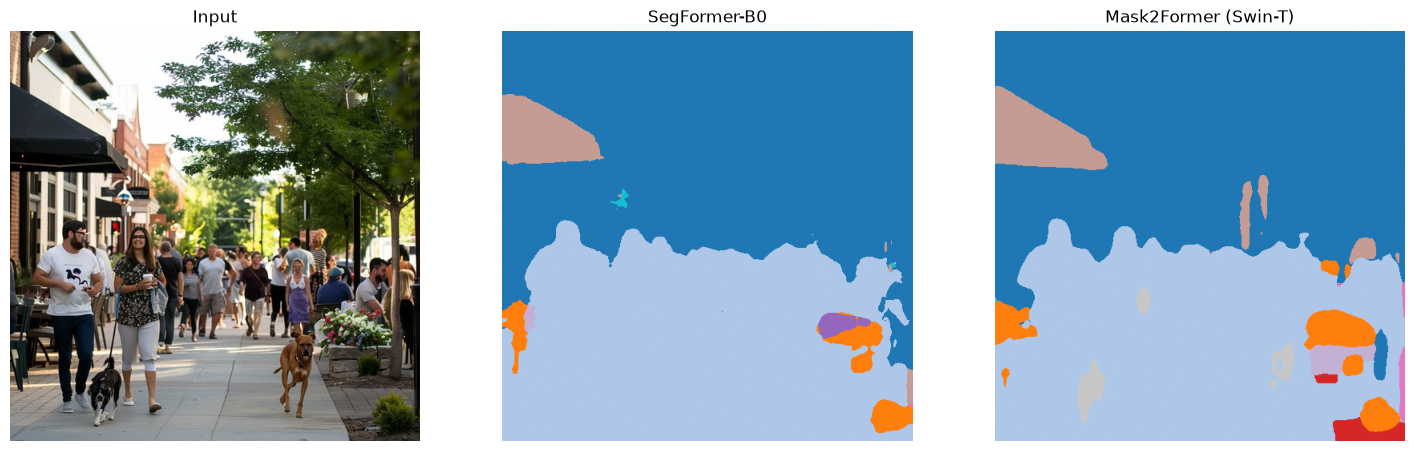

In [5]:
m2f_processor = Mask2FormerImageProcessor.from_pretrained("facebook/mask2former-swin-tiny-ade-semantic")
mask2former = Mask2FormerForUniversalSegmentation.from_pretrained("facebook/mask2former-swin-tiny-ade-semantic").eval()

with torch.no_grad():
    m2f_out = mask2former(**m2f_processor(images=image, return_tensors="pt"))

print("class_queries_logits:", tuple(m2f_out.class_queries_logits.shape), "<- (B, N queries, K + 1)")
print("masks_queries_logits:", tuple(m2f_out.masks_queries_logits.shape), "<- (B, N queries, H/4, W/4)")

mask2former_mask = m2f_processor.post_process_semantic_segmentation(m2f_out, target_sizes=[image.size[::-1]])[0]

# Обе модели обучены на ADE20K (150 классов) -> одинаковые индексы классов, сравниваем в одной палитре
id2label = segformer.config.id2label
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(image)
axs[0].set_title("Input")
for ax, m, title in zip(axs[1:], [segformer_mask, mask2former_mask], ["SegFormer-B0", "Mask2Former (Swin-T)"]):
    ax.imshow(m.numpy(), cmap="tab20", vmin=0, vmax=149)
    ax.set_title(title)
for ax in axs:
    ax.axis("off")

for name, m in [("SegFormer", segformer_mask), ("Mask2Former", mask2former_mask)]:
    ids, counts = m.unique(return_counts=True)
    top = sorted(zip(counts.tolist(), ids.tolist()), reverse=True)[:6]
    print(f"{name:>11}: " + ", ".join(f"{id2label[i]} {c / m.numel():.0%}" for c, i in top))